# CLIP (Contrastive Language-Image Pre-training))
[A. Radford, J. W. Kim, C. Hallacy, et al., "Learning Transferable Visual Models from Natural Language Supervision" arXiv, 2021.](https://arxiv.org/abs/2103.00020)

* New approch to link images and texts, enabling scalable supervised learning by using natural language

* Contrastive pre-training
  1. Extract feature representations of each modality.
```
I_f = image_encoder(image) # [N, D_i]
T_f = text_encoder(text)   # [N, D_t]
```
```
I_e = l2_normalize(np.dot(I_f, W_i), axis=1)
T_e = l2_normalize(np.dot(T_f, W_t), axis=1)
```

  2. Calculate the cosin similarity for each pair.
```
logits = np.dot(I_e, T_e.T) * np.exp(t)  # [N, N]
```

  3. Campute the cross-entropy using symmetric loss function.
```
labels = np.arange(n)
loss_i = cross_entropy_loss(logits, labels, axis=0)
loss_t = cross_entropy_loss(logits, labels, axis=1)
loss = (loss_i + loss_t)/2
```

* Zero-shot prediction
  1. Create a list of label text: `A photo of a {class_name}`
  2. Extract feature representations from input images and the above text list<br>
     and calculate the similarity for each label text
  3. Pick the text with highest score as the answer


In [1]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive')

DATA_ROOT= Path('./data/')
MODEL_ROOT = DRIVE_ROOT / 'weights'

!mkdir -p {DATA_ROOT}
!mkdir -p {MODEL_ROOT}

Mounted at /content/drive


In [2]:
%pip install -q matplotlib torchviz torchinfo
%pip -q install "git+https://github.com/openai/CLIP.git"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.7 MB/s eta 0:00:00


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm.notebook import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, ops, transforms

%matplotlib inline
plt.rcParams['font.size'] = 14
plt.rcParams['figure.figsize'] = (3, 3)
plt.rcParams['axes.grid'] = True
np.set_printoptions(suppress=True, precision=4)

def get_device():
    '''Get device (CPU or GPU).'''
    return torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## Quick Hands-on with CLIP Zero-shot Prediction

In [4]:
!rsync -auv --info=progress2 {DRIVE_ROOT}/datasets/food-101.tar.gz {DATA_ROOT}/
food_dataset = datasets.Food101(root=DATA_ROOT, download=True)
classes = food_dataset.classes

sending incremental file list
food-101.tar.gz
  4,996,278,331 100%   58.71MB/s    0:01:21 (xfr#1, to-chk=0/1)

sent 4,997,498,228 bytes  received 35 bytes  60,575,736.52 bytes/sec
total size is 4,996,278,331  speedup is 1.00


In [5]:
@torch.inference_mode()
def predict(model, image, texts, device=get_device()):
    """ Predict the similarity between an input image and candidate texts.

    Args:
        model: Inference model.
        image: Input image [C, H, W].
        texts: List of candidate text.
    Returns:
        torch.Tensor: Probability scores over the text candidates [N_class].
    """
    model.to(device)
    model.eval()

    # Extract feature representations of input image.
    image = image.unsqueeze(0).to(device)  # [1, C, H, W]
    image_f = model.encode_image(image)    # [1, D]
    image_f /= image_f.norm(dim=-1, keepdim=True)

    # Extract feature representations of input texts.
    tokens = clip.tokenize(texts).to(device)  # [N_class, token_length]
    texts_f = model.encode_text(tokens)       # [N_class, D]
    texts_f /= texts_f.norm(dim=-1, keepdim=True)

    # Compute scaled cosine similarities between the image and text features.
    scale_factor = model.logit_scale.exp()
    logits = (image_f @ texts_f.T).squeeze(0) * scale_factor  # [N_class]
    scores = logits.softmax(dim=-1)                           # [N_class]

    return scores.cpu()


def visualize(input, texts, output, figsize=(6,3), topk=5):
    """ Visualize an input image and picked up topk candidate.

    Args:
        input: (image, label)
        texts: List of candidate text.
        scores: Probability scores over the text candidates [N_class].
    """
    image, label = input
    top_scores, top_idx = scores.topk(topk)

    fig = plt.figure(figsize=figsize, constrained_layout=True)
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 2], wspace=0.05)

    ax_img = fig.add_subplot(gs[0])
    ax_img.imshow(image)
    ax_img.axis("off")

    ax_txt = fig.add_subplot(gs[1])
    captions = [
        f'Ground Truth: {texts[label]}',
        'Prediction:'
    ] + [f"{i+1}. {texts[top_idx[i]]}: {top_scores[i]:.2f}" for i in range(topk)]
    ax_txt.text(0, 1, '\n'.join(captions), ha="left", va="top")
    ax_txt.axis("off")

    plt.show()

100%|███████████████████████████████████████| 338M/338M [00:06<00:00, 56.4MiB/s]


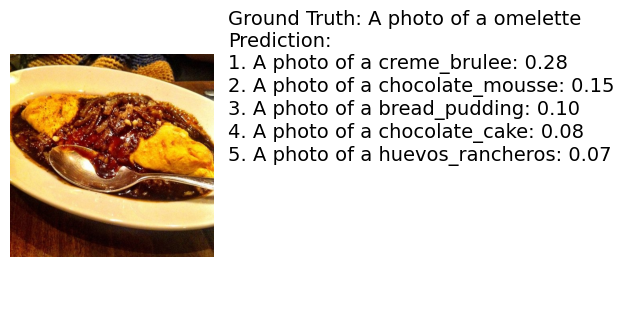

In [6]:
import clip
import random

# Pick a pair of image and text randomly.
rand_idx = random.randrange(len(food_dataset))
image, label = food_dataset[rand_idx]

# Prepare description candidates.
texts = [f"A photo of a {class_name}" for class_name in classes]

model, preprocess = clip.load("ViT-B/32")
scores = predict(model, preprocess(image), texts)
visualize((image, label), texts, scores)

## Contrastive pre-training

### Model

In [7]:
class ImageTransform():
    def __init__(self, image_size=224, mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616)):
        self.transform = transforms.Compose([
            transforms.Resize(size=image_size, interpolation=Image.BICUBIC, antialias=True),
            transforms.CenterCrop(size=(image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std),
        ])

    def __call__(self, image):
        return self.transform(image)

In [8]:
from torch import nn
from torchvision.models import vit_b_32, ViT_B_32_Weights

class VisionEncoder(nn.Module):
    def __init__(self, emb_dim=512, pretrained=True):
        super().__init__()
        self.vision_encoder = vit_b_32(weights=ViT_B_32_Weights.DEFAULT)
        hidden_dim = self.vision_encoder.heads[-1].in_features
        self.vision_encoder.heads = nn.Linear(hidden_dim, emb_dim, bias=False)

    def forward(self, x):
        return self.vision_encoder(x)

vision_encoder = VisionEncoder()
image_t = ImageTransform()(image).unsqueeze(0)  # [1, C, H, W]
x = vision_encoder(image_t)
x.shape

Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:08<00:00, 41.4MB/s]


torch.Size([1, 512])

In [9]:
from dataclasses import dataclass

@dataclass
class TextEncoderParameter:
    """ Parameters for CLIP."""
    context_length: int = 77  # Sequence length for text tokens.
    text_width: int = 512     # Hidden dimension in encoder.
    text_heads: int = 8       # Number of attention heads.
    text_layers: int = 12     # Number of encoder layers.
    ffn_mult: int = 4         # Multiplier for FFN hidden size
    embed_dim: int = 512      # Output dimension.
    dropout_rate: float = 0.0

In [10]:
from transformers import CLIPTokenizerFast

class CLIPTokenizer:
    """ Tokenizer for CLIP."""
    def __init__(self, model_name="openai/clip-vit-base-patch32"):
        self.tokenizer = CLIPTokenizerFast.from_pretrained(model_name)

    def __call__(self, text: str):
        return self.tokenizer(text, padding="max_length", truncation=True, return_tensors="pt")['input_ids']

    @property
    def vocab_size(self) -> int:
        """ Return the number of vocabulary in this model (= The number of token class)."""
        return self.tokenizer.vocab_size

tokenizer = CLIPTokenizer()
print('Vocab size: ', tokenizer.vocab_size)
display(tokenizer('This is a photo of dog.'))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Vocab size:  49408


tensor([[49406,   589,   533,   320,  1125,   539,  1929,   269, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407]])

In [11]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size: int, param: TextEncoderParameter):
        super().__init__()
        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=param.text_width,
            padding_idx=0,
        )

        self.positional_embedding = nn.Parameter(
            torch.empty(param.context_length, param.text_width))

        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=param.text_width,
                nhead=param.text_heads,
                dim_feedforward=param.ffn_mult * param.text_width,
                dropout=param.dropout_rate,
                activation="gelu",
                batch_first=False,
                norm_first=True,
            ),
            num_layers=param.text_layers,
            enable_nested_tensor=False  # Just for suppressing warning.
        )

        self.layer_norm = nn.LayerNorm(param.text_width)
        self.text_projection = nn.Parameter(torch.empty(param.text_width, param.embed_dim))

        # Initialize network parameters.
        self.reset_parameter(param.text_width)

    def reset_parameter(self, text_width):
        nn.init.normal_(self.token_embedding.weight, std=0.02)
        nn.init.normal_(self.positional_embedding, std=0.01)
        nn.init.normal_(self.text_projection, std=text_width ** -0.5)

    def forward(self, x: torch.Tensor):
        """
        Args:
            x: Input tokens (B, L), where
                B: Batch size.
                L: Context length.
        Returns:
            torch.Tensor: (B, E), where
                E: Embedding dimension.
        """
        # Embed input tokens.
        # (B, L, D), where D denotes the hidden dimensions (text_width) in Transformer.
        x = self.token_embedding(x) + self.positional_embedding

        # Apply transformer and normalize the output.
        x = x.permute(1, 0, 2)  # (B, L, D) -> (L, B, D)
        x = self.transformer(x)
        x = x.permute(1, 0, 2)  # (L, B, D) -> (B, L, D)
        x = self.layer_norm(x)

        # Pick up the position of EOT (= The highest number in each sequence.)
        eot_idx = token_seq.argmax(dim=-1)         # [B]
        x = x[torch.arange(x.shape[0]), eot_idx]   # [B, D]

        # Project to output.
        x = x @ self.text_projection               # [B, D] @ [D, E] -> [B, E]
        return x

tokenizer = CLIPTokenizer()
text_encoder = TextEncoder(vocab_size=tokenizer.vocab_size, param=TextEncoderParameter())
token_seq = tokenizer('This is a photo of frog.')
x = text_encoder(token_seq)
x.shape

torch.Size([1, 512])

In [12]:
class CLIP(nn.Module):
    def __init__(self, vocab_size: int, param: TextEncoderParameter):
        super().__init__()
        self.vision_encoder = VisionEncoder(emb_dim=param.embed_dim)
        self.text_encoder = TextEncoder(vocab_size=vocab_size, param=param)
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

    def encode_image(self, image: torch.Tensor):
        return self.vision_encoder(image)

    def encode_text(self, token_seq: torch.Tensor):
        return self.text_encoder(token_seq)

    def forward(self, image: torch.Tensor, token_seq: torch.Tensor):
        # Encode input image and token sequence.
        image_f = self.encode_image(image)
        text_f = self.encode_text(token_seq)

        # Normalize features
        image_f = image_f.norm(dim=-1, keepdim=True)
        text_f = text_f.norm(dim=-1, keepdim=True)

        # Calculate cosine similarities as logits
        logit_scale = self.logit_scale.exp().clamp(max=100.0)
        logits_per_image = logit_scale * image_f @ text_f.t()
        logits_per_text = logits_per_image.t()
        return logits_per_image, logits_per_text

model = CLIP(vocab_size=tokenizer.vocab_size, param=TextEncoderParameter())
model(image_t, token_seq)

(tensor([[2764.7205]], grad_fn=<MmBackward0>),
 tensor([[2764.7205]], grad_fn=<TBackward0>))

In [13]:
del image, token_seq

### Dataset and dataloader

In [14]:
%pip install -q huggingface_hub

In [15]:
!rsync -auv --info=progress2 {DRIVE_ROOT}/datasets/flickr30k-images.zip {DATA_ROOT}/

sending incremental file list
flickr30k-images.zip
  4,390,240,817 100%   32.17MB/s    0:02:10 (xfr#1, to-chk=0/1)

sent 4,391,312,759 bytes  received 35 bytes  33,394,013.64 bytes/sec
total size is 4,390,240,817  speedup is 1.00


In [16]:
@dataclass
class Config:
    """ Configuration for model training, validation, and inference."""
    num_epochs: int = 3
    batch_size: int = 32
    lr: float = 1e-4
    weight_decay: float = 0.05

In [17]:
from huggingface_hub import snapshot_download
import json
import pandas as pd
import zipfile

class Flikr30kDataset(Dataset):
    REPO_ID = "nlphuji/flickr30k"
    IMAGE_DIRNAME = "flickr30k-images"
    ANN_CSV_FILE = "flickr_annotations_30k.csv"
    ANN_TSV_FILE = "flickr_annotation_{split}_30k.csv"

    def __init__(self, root: Path, phase='train', download=True, transform=None, target_transform=None):
        if download:
            self._download_dataset(root)

            input_filepath = root / self.ANN_CSV_FILE
            self._convert_csv_to_ann(input_filepath, root)

        image_dirpath = root / self.IMAGE_DIRNAME
        ann_filepath = root / self.ANN_TSV_FILE.format(split=phase)
        self.dataset = datasets.Flickr30k(root=image_dirpath, ann_file=ann_filepath,
                                          transform=transform, target_transform=target_transform)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        return self.dataset[idx]

    def _download_dataset(self, root: Path):
        zip_path = root / (self.IMAGE_DIRNAME + ".zip")
        if (root/self.IMAGE_DIRNAME).exists():
            return

        snapshot_download(self.REPO_ID, local_dir=root, repo_type="dataset")
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(root)

    def _convert_csv_to_ann(self, input_file: Path, output_dir: Path):
        df = pd.read_csv(input_file)
        df = df[['filename', 'raw', 'split']].dropna().astype(str)
        df['filename'] += '#0'
        df['raw'] = df['raw'].apply(lambda x: json.loads(x))
        df = df.explode('raw').reset_index(drop=True)

        for split, group in df.groupby('split'):
            output_filepath = output_dir / self.ANN_TSV_FILE.format(split=split)
            group[["filename", "raw"]].to_csv(output_filepath, sep='\t', index=False)

In [18]:
from typing import List

def collate_fn(batch: List[tuple]) -> tuple:
    """
    Args:
        batch: List of pairs (image, list of token_seq)
            - image: [C, H, W], list of token_seq: [K, L]
    Returns:
        image: Tensor [B*K, C, H, W],
        token_seqs: [B*K, L])
    """
    images, token_seqs = zip(*batch)
    K = len(token_seqs[0])

    # Expand along token_seq list size and flatten
    # [B, C, H, W] -(expand)-> [B, K, C, H, W] -(flatten)-> [B*K, C, H, W]
    images = torch.stack(images, dim=0)
    images = images.unsqueeze(1).expand(-1, K, -1, -1, -1)
    images = images.flatten(0, 1)

    # [B, K, L] -> [B*K, L]
    token_seqs = torch.stack(token_seqs, dim=0)
    token_seqs = token_seqs.flatten(0, 1)

    return images, token_seqs

In [19]:
config = Config()

train_dataset = Flikr30kDataset(
    root=DATA_ROOT, phase='train', transform=ImageTransform(), target_transform=tokenizer)
test_dataset = Flikr30kDataset(
    root=DATA_ROOT, phase='val', transform=ImageTransform(), target_transform=tokenizer)

train_loader = DataLoader(train_dataset, batch_size=config.batch_size//2, shuffle=True,
                          collate_fn=collate_fn, num_workers=1, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False,
                         collate_fn=collate_fn, num_workers=2, pin_memory=True)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

README.md:   0%|          | 0.00/641 [00:00<?, ?B/s]

flickr30k.py: 0.00B [00:00, ?B/s]

flickr_annotations_30k.csv:   0%|          | 0.00/12.9M [00:00<?, ?B/s]

### Train and validate

In [20]:
def train(model, criterion, optimizer, scheduler, data_loader, device):
    n_data = 0
    total_loss = 0
    total_correct = 0

    model.train()
    for inputs, labels in tqdm(data_loader, desc='Train', leave=False):
        batch_size = len(labels)
        n_data += batch_size

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        predicted = torch.max(outputs, 1)[1]
        total_loss += loss.item() * batch_size
        total_correct += (predicted == labels).sum().item()
    return total_loss/n_data, total_correct/n_data


@torch.no_grad()
def test(model, criterion, data_loader, device):
    n_data = 0
    total_loss = 0
    total_correct = 0

    model.eval()
    for inputs, labels in tqdm(data_loader, desc='Test', leave=False):
        batch_size = len(labels)
        n_data += batch_size

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        predicted = torch.max(outputs, 1)[1]
        total_loss += loss.item() * batch_size
        total_correct += (predicted == labels).sum().item()
    return total_loss/n_data, total_correct/n_data


def train_and_test(num_epochs, model, criterion, optimizer, scheduler, train_loader, test_loader):
    device = get_device()
    train_history = []
    test_history = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train(model, criterion, optimizer, scheduler, train_loader, device)
        test_loss, test_acc = test(model, criterion, test_loader, device)

        train_history.append([epoch, train_loss, train_acc])
        test_history.append([epoch, test_loss, test_acc])
        print(f'Epoch [{epoch+1}/{num_epochs}], loss: {train_loss:.5f} acc: {train_acc:.5f} test_loss: {test_loss:.5f}, test_acc: {test_acc:.5f}')

    return train_history, test_history